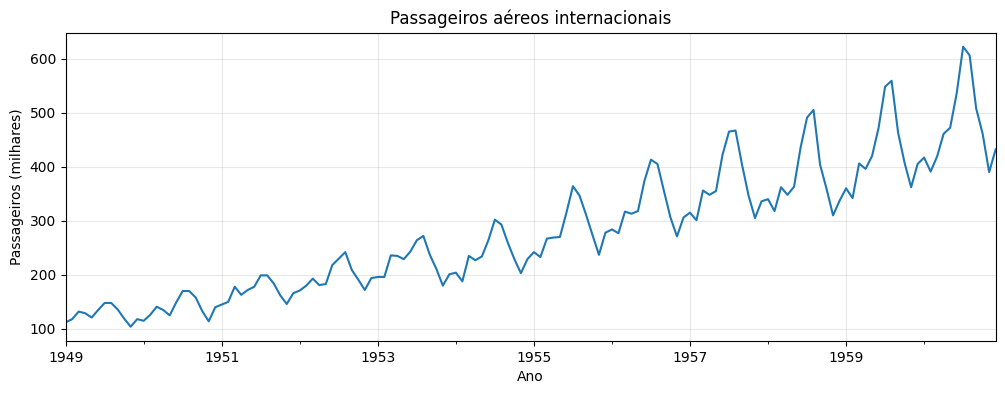

In [ ]:
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt

dados = sm.datasets.get_rdataset(
    "AirPassengers", package="datasets"
).data

serie = pd.Series(
    dados["value"].to_numpy(),
    index=pd.date_range("1949-01-01", periods=len(dados), freq="MS"),
    name="Passageiros"
)

serie.plot(figsize=(12, 4))
plt.title("Passageiros aéreos internacionais")
plt.xlabel("Ano")
plt.ylabel("Passageiros (milhares)")
plt.grid(alpha=0.3)
plt.show()

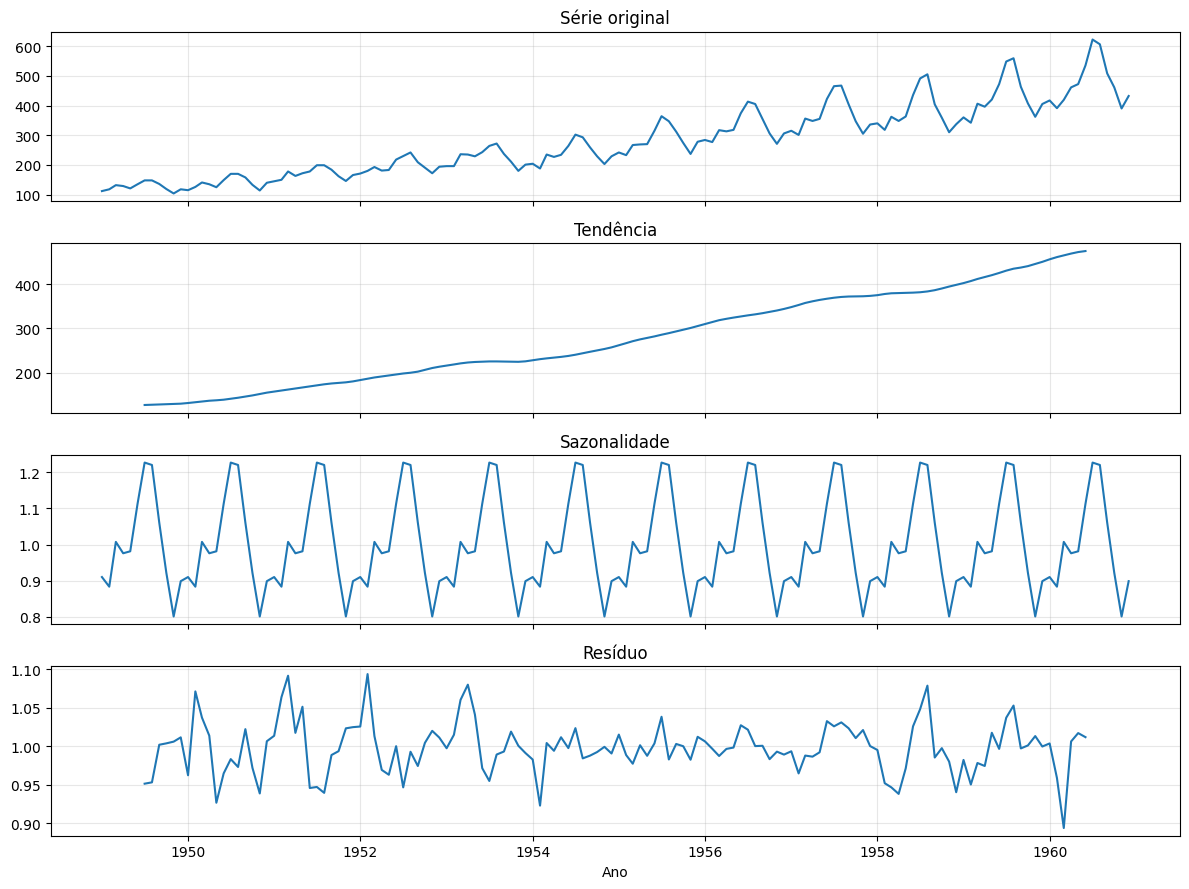

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose


decomposicao = seasonal_decompose(
    serie,
    model="multiplicative",
    period=12
)

fig, eixos = plt.subplots(4, 1, figsize=(12, 9), sharex=True)

componentes = [
    (serie, "Série original"),
    (decomposicao.trend, "Tendência"),
    (decomposicao.seasonal, "Sazonalidade"),
    (decomposicao.resid, "Resíduo")
]

for eixo, (valores, titulo) in zip(eixos, componentes):
    eixo.plot(valores)
    eixo.set_title(titulo)
    eixo.grid(alpha=0.3)

eixos[-1].set_xlabel("Ano")
plt.tight_layout()
plt.show()

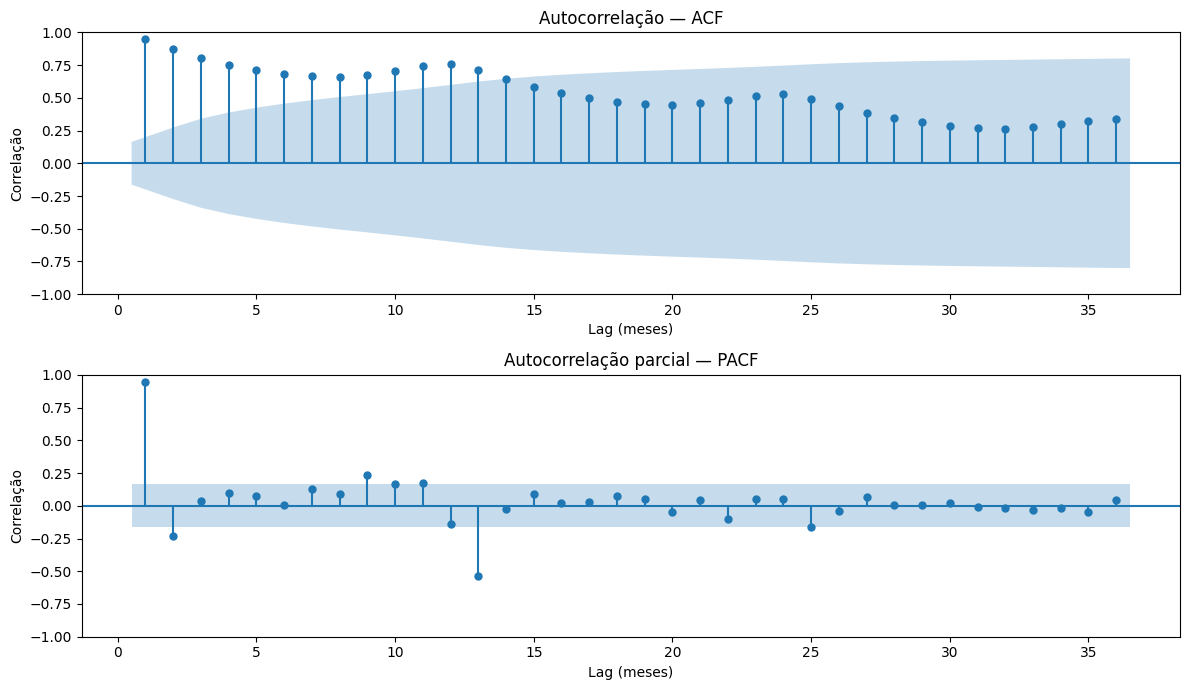

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf


fig, eixos = plt.subplots(2, 1, figsize=(12, 7))

plot_acf(serie, lags=36, zero=False, ax=eixos[0])
eixos[0].set_title("Autocorrelação — ACF")

plot_pacf(
    serie,
    lags=36,
    zero=False,
    method="ywm",
    ax=eixos[1]
)
eixos[1].set_title("Autocorrelação parcial — PACF")

for eixo in eixos:
    eixo.set_xlabel("Lag (meses)")
    eixo.set_ylabel("Correlação")

plt.tight_layout()
plt.show()

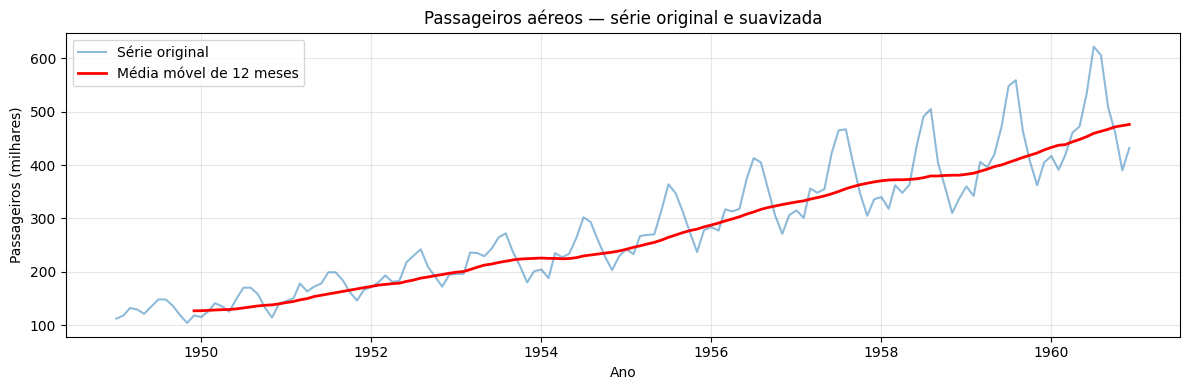

In [ ]:
suavizada = serie.rolling(window=12).mean()

plt.figure(figsize=(12, 4))

plt.plot(serie, label="Série original", alpha=0.5)
plt.plot(
    suavizada,
    label="Média móvel de 12 meses",
    color="red",
    linewidth=2
)

plt.title("Passageiros aéreos — série original e suavizada")
plt.xlabel("Ano")
plt.ylabel("Passageiros (milhares)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

treino = serie.iloc[:-36]
teste = serie.iloc[-36:]

previsoes = pd.DataFrame(index=teste.index)

# Ingênuo: repete o último valor observado
previsoes["Ingênuo"] = treino.iloc[-1]

# Sazonal ingênuo: repete o último ano observado três vezes
previsoes["Sazonal ingênuo"] = np.tile(
    treino.iloc[-12:].to_numpy(), 3
)

# ARIMA sem componente sazonal explícito
ajuste = ARIMA(treino, order=(5, 1, 5)).fit()

previsoes["ARIMA"] = ajuste.forecast(steps=36).to_numpy()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


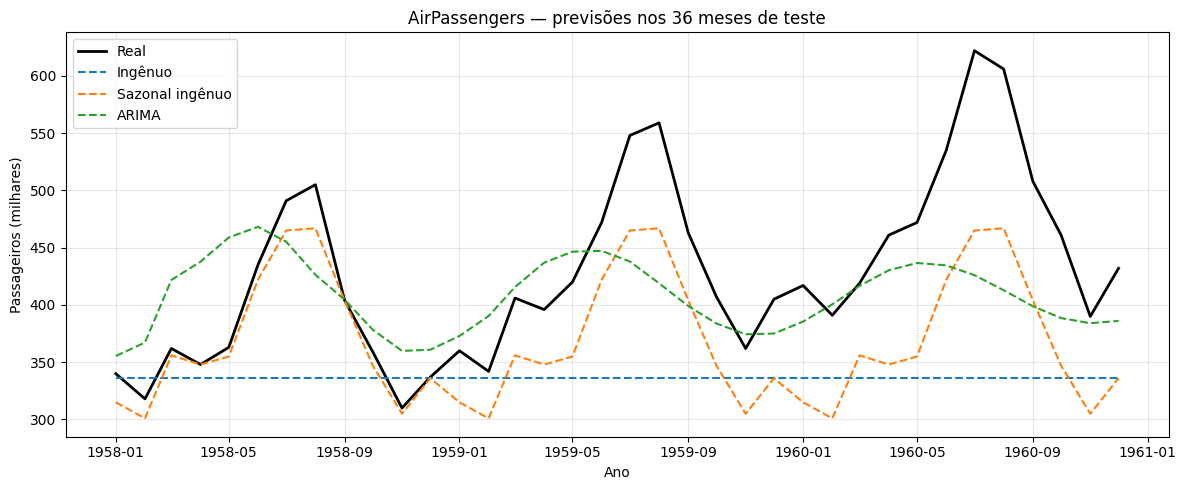

In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    teste,
    label="Real",
    color="black",
    linewidth=2
)

for nome in previsoes.columns:
    plt.plot(previsoes[nome], label=nome, linestyle="--")

plt.title("AirPassengers — previsões nos 36 meses de teste")
plt.xlabel("Ano")
plt.ylabel("Passageiros (milhares)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
!pip -q install xgboost

In [ ]:
from xgboost import XGBRegressor

tabela = pd.DataFrame({"alvo": treino})

for lag in range(1, 13):
    tabela[f"lag_{lag}"] = treino.shift(lag)

# Representação cíclica do mês
tabela["mes_seno"] = np.sin(2 * np.pi * tabela.index.month / 12)
tabela["mes_cosseno"] = np.cos(2 * np.pi * tabela.index.month / 12)

tabela = tabela.dropna()

X_treino = tabela.drop(columns="alvo")
y_treino = tabela["alvo"]

display(tabela.head())

modelo_xgb = XGBRegressor(
    n_estimators=200,
    max_depth=3,
    learning_rate=0.05,
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

modelo_xgb.fit(X_treino, y_treino)

,alvo,lag_1,lag_2,lag_3,lag_4,lag_5,lag_6,lag_7,lag_8,lag_9,lag_10,lag_11,lag_12,mes_seno,mes_cosseno
1950-01-01,115,118.0,104.0,119.0,136.0,148.0,148.0,135.0,121.0,129.0,132.0,118.0,112.0,0.500000,8.660254e-01
1950-02-01,126,115.0,118.0,104.0,119.0,136.0,148.0,148.0,135.0,121.0,129.0,132.0,118.0,0.866025,5.000000e-01
1950-03-01,141,126.0,115.0,118.0,104.0,119.0,136.0,148.0,148.0,135.0,121.0,129.0,132.0,1.000000,6.123234e-17
1950-04-01,135,141.0,126.0,115.0,118.0,104.0,119.0,136.0,148.0,148.0,135.0,121.0,129.0,0.866025,-5.000000e-01
1950-05-01,125,135.0,141.0,126.0,115.0,118.0,104.0,119.0,136.0,148.0,148.0,135.0,121.0,0.500000,-8.660254e-01


XGBRegressor(base_score=None, booster=None, callbacks=None,
             colsample_bylevel=None, colsample_bynode=None,
             colsample_bytree=None, device=None, early_stopping_rounds=None,
             enable_categorical=True, eval_metric=None, feature_types=None,
             feature_weights=None, gamma=None, grow_policy=None,
             importance_type=None, interaction_constraints=None,
             learning_rate=0.05, max_bin=None, max_cat_threshold=None,
             max_cat_to_onehot=None, max_delta_step=None, max_depth=3,
             max_leaves=None, min_child_weight=None, missing=nan,
             monotone_constraints=None, multi_strategy=None, n_estimators=200,
             n_jobs=-1, num_parallel_tree=None, ...)

In [ ]:
historico = treino.tolist()
predicoes_xgb = []

for data in teste.index:

    entradas = {
        f"lag_{lag}": historico[-lag]
        for lag in range(1, 13)
    }

    entradas["mes_seno"] = np.sin(2 * np.pi * data.month / 12)
    entradas["mes_cosseno"] = np.cos(2 * np.pi * data.month / 12)

    linha = pd.DataFrame(
        [entradas],
        columns=X_treino.columns
    )

    predicao = float(modelo_xgb.predict(linha)[0])

    predicoes_xgb.append(predicao)
    historico.append(predicao)  # Acrescenta a previsão, não o valor real

previsoes["XGBoost"] = predicoes_xgb

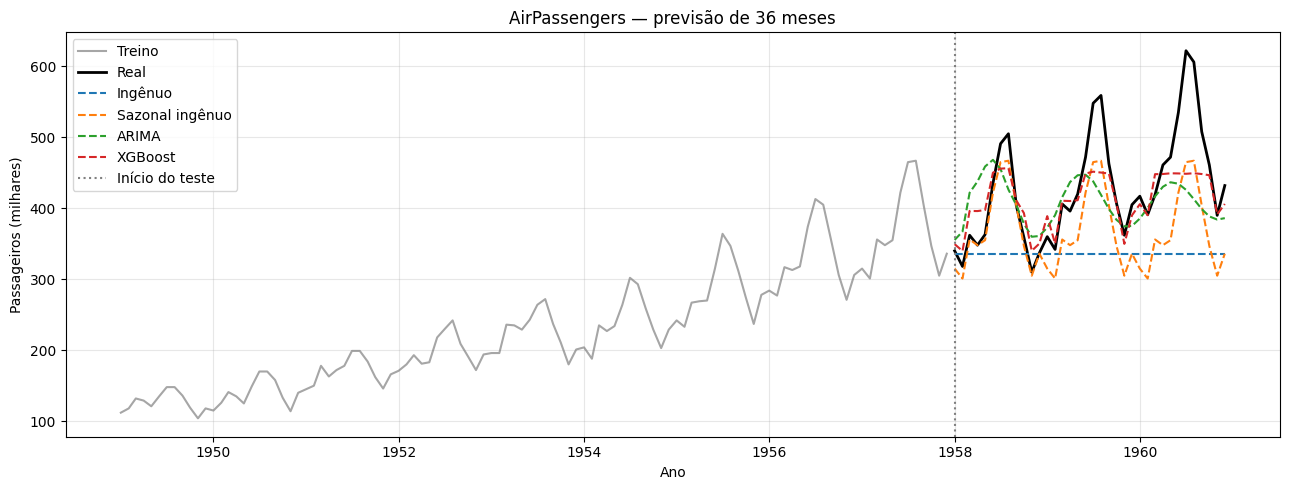

In [ ]:
plt.figure(figsize=(13, 5))

plt.plot(treino, label="Treino", color="gray", alpha=0.7)
plt.plot(teste, label="Real", color="black", linewidth=2)

for nome in previsoes.columns:
    plt.plot(previsoes[nome], label=nome, linestyle="--")

plt.axvline(
    teste.index[0],
    color="gray",
    linestyle=":",
    label="Início do teste"
)

plt.title("AirPassengers — previsão de 36 meses")
plt.xlabel("Ano")
plt.ylabel("Passageiros (milhares)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
from sklearn.metrics import r2_score

metricas = []

for nome in previsoes.columns:
    erros = teste - previsoes[nome]

    metricas.append({
        "Modelo": nome,
        "MAE": np.abs(erros).mean(),
        "RMSE": np.sqrt((erros ** 2).mean()),
        "R²": r2_score(teste, previsoes[nome])
    })

metricas = (
    pd.DataFrame(metricas)
    .set_index("Modelo")
    .sort_values("MAE")
)

display(metricas.round(3))

,MAE,RMSE,R²
Modelo,,,
XGBoost,35.006,53.452,0.533
ARIMA,53.520,72.049,0.152
Sazonal ingênuo,60.083,73.612,0.114
Ingênuo,94.944,121.139,-1.398
